# Data figures for arXiv:2611.02972

This notebook makes the data figures of the paper "Towards Optimal Routing Strategies for qLDPC codes on Silicon Spin Qubits".

- The notebook reads the simulation results from the `data/` folder.
- The notebook writes the figures as PDF files to the `figures/` folder.
- Run all cells from top to bottom. The notebook does not run any simulations.

The authors edited the published Figures 2 and 3 by hand after this notebook made them (legend position and layout). The files that this notebook writes show the values in the data.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import seaborn as sns

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Leave the creation date out of the PDF files, so that a new run gives the same files.
PDF_METADATA = {"CreationDate": None}



#The collection of parameters are: "Noise Dependence", "Strategy", "Polarization", "Noise Sources", "Idling to Error Ratio", "Shuttling Error Ratio", "Grid Type"
#There is also a term "Idling Error Ratio", but it's better to work with Idling to Error Ratio.
#Eta Shuttling == 0.5 corresponds to depolarized noise. Eta Shuttling == 100 is polarized noise.

## Strategy datasweep

Load the strategy datasweep and the baseline runs. Then give the parameters readable names.

In [2]:
file_path = os.path.join(DATA_DIR, 'compiled_results_complete.csv')
df = pd.read_csv(file_path)

file_path_baseline = os.path.join(DATA_DIR, 'compiled_results_baseline.csv')
baseline_df = pd.read_csv(file_path_baseline)


In [3]:
df["Strategy"] = df["Strategy"].replace("total_shuttling_minimized","Total Shuttling Minimized")
df["Strategy"] = df["Strategy"].replace("maximum_matching_efficient","Minimize Largest Distance")
df["Strategy"] = df["Strategy"].replace("min_weight_matching_efficient","Combined")

df = df.rename(columns={"Noise Model" : "Noise Dependence", "Eta Shuttling" : "Polarization", "2 Qubit Gate Error" : "Noise Sources"})

df["Polarization"] = df["Polarization"].replace(0.5, "Depolarized")
df["Polarization"] = df["Polarization"].replace(100, "Polarized")


df["Noise Sources"] = df["Noise Sources"].replace(1.0, "Full")
df["Noise Sources"] = df["Noise Sources"].replace(0, "Shuttling & Idling")

baseline_df = baseline_df.rename(columns={"Noise Model" : "Noise Dependence", "Eta Shuttling" : "Polarization", "2 Qubit Gate Error" : "Noise Sources"})

baseline_df["Polarization"] = baseline_df["Polarization"].replace(0.5, "Depolarized")
baseline_df["Polarization"] = baseline_df["Polarization"].replace(100, "Polarized")




### Figure 8 (Appendix C)

This cell writes `figures/Comparison_plot_appendix.pdf`. The paper uses this file as Figure 8.

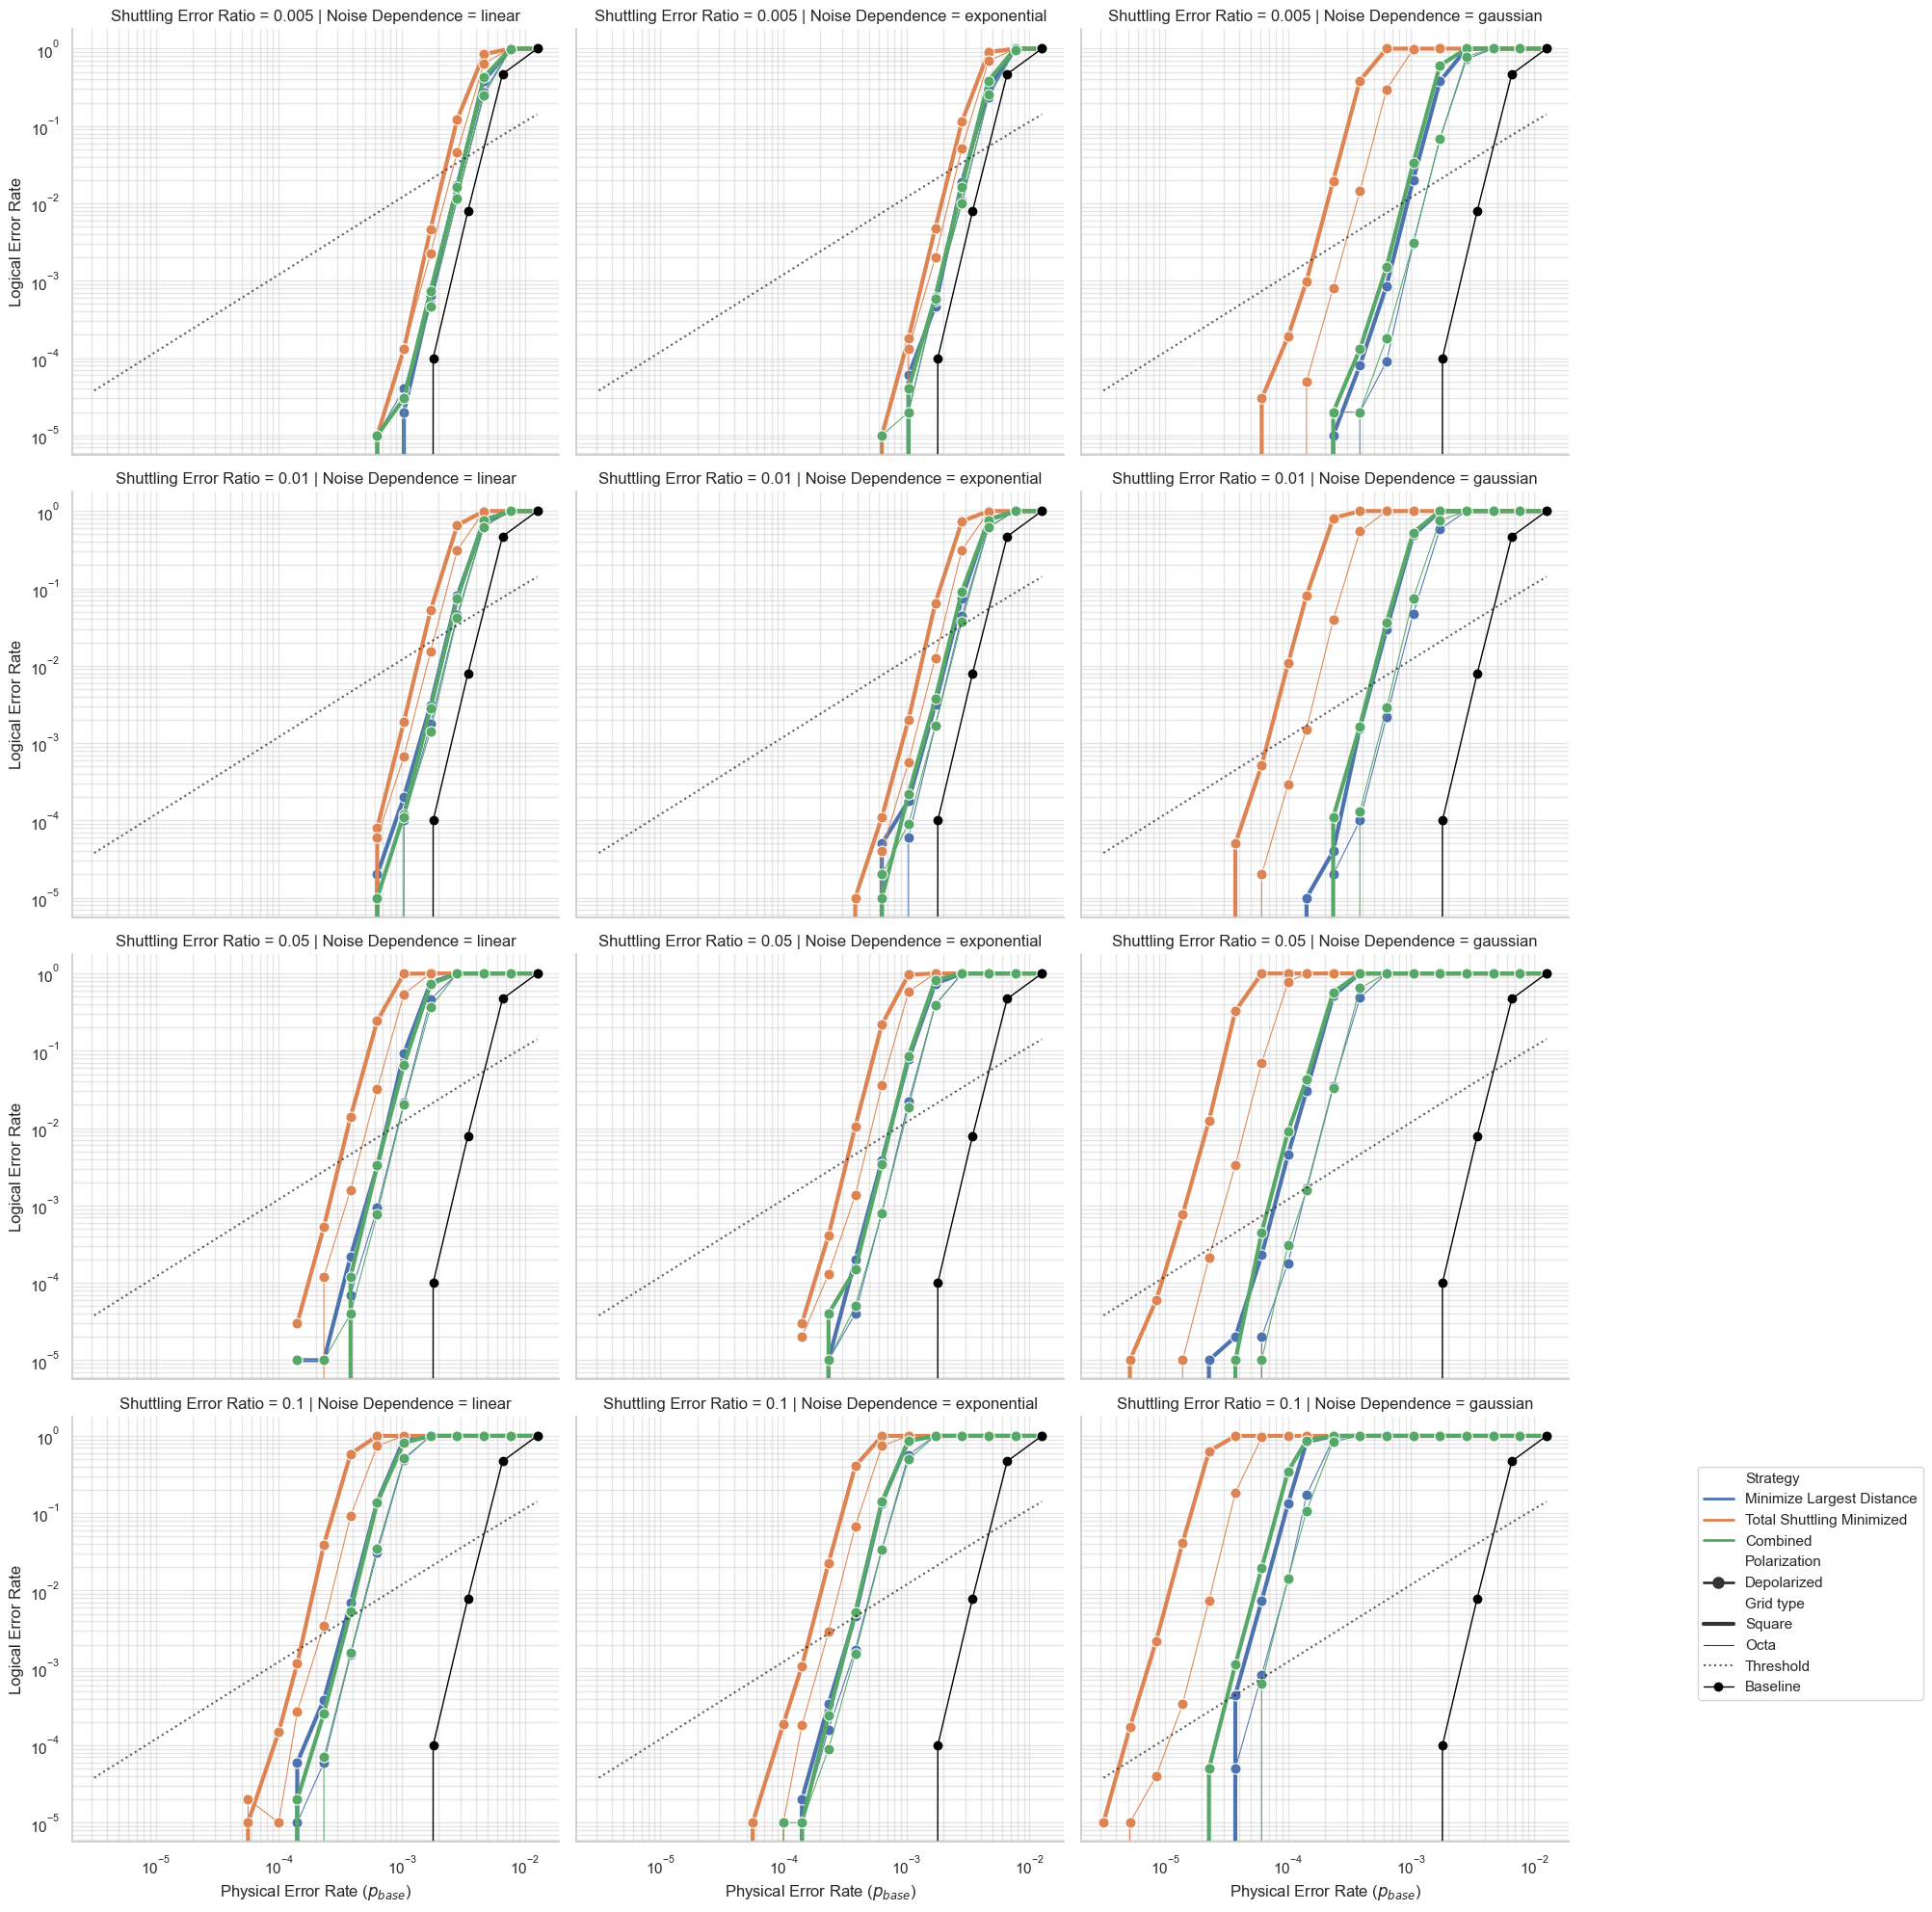

In [4]:
sns.set_theme(style="whitegrid")


base_df = baseline_df[(baseline_df["Polarization"] == "Depolarized")]

g = sns.relplot(
    data=df[(df["Polarization"] == "Depolarized") &
            (df["Noise Sources"] == "Full") &
            (df["Idling to Error Ratio"] == 1.8)],# [
    #     (df["Noise Sources"] == "Full")
    #     & (df["Idling Error Ratio"] == 0.0017)
    #     & (df["Noise Dependence"].isin(["linear", "gaussian"]))
    # ],
    kind="line",
    x="Physical Error Rate",
    y="Logical Error Rate",
    hue="Strategy",  # Perfect for comparing 'linear' vs 'gaussian'
    style="Polarization",  # The "Polarization" can now easily distinguish bias vs no bias
    row="Shuttling Error Ratio",
    col="Noise Dependence",
    size="Grid type",
    markers=True,
    dashes=True,
    linewidth=2,
    markersize=8,
    height=5,
    aspect=1.2,
)

g.set(xscale="log", yscale="log")

min_p = df["Physical Error Rate"].min()
max_p = df["Physical Error Rate"].max()

x_vals = np.linspace(min_p, max_p,100)
y_vals = [1 - (1 - x_val)**12 for x_val in x_vals]

for ax in g.axes.flat:
    ax.plot(
        x_vals,
        y_vals,
        "k:",
        alpha=0.7,
        label="Threshold",
    )
    ax.grid(True, which="both", ls="-", alpha=0.5)

#Adds baseline plot into every plot of the grid.
for ax in g.axes.flat:
    ax.plot(
        base_df["Physical Error Rate"],
        base_df["Logical Error Rate"],
        color = "black",
        linestyle="-", 
        linewidth=1,
        marker="o",
        label="Baseline"
    )

# for ax in g.axes.flat:
#     ax.plot(
#         [min_p, max_p],
#         [12*min_p, 12*max_p],
#         "k:",
#         alpha=0.7,
#         label="Threshold",
#     )
#     ax.grid(True, which="both", ls="-", alpha=0.5)

g.set_axis_labels("Physical Error Rate ($p_{base}$)", "Logical Error Rate")


#Extract handles and labels from the existing sns legend
sns_handles = g.legend.legend_handles
sns_labels = [text.get_text() for text in g.legend.texts]

# Extract all handles/labels from the first axis
ax_handles, ax_labels = g.axes.flat[0].get_legend_handles_labels()

# Create a dictionary mapping the label names to their respective handles
ax_dict = dict(zip(ax_labels, ax_handles))

# Extract exactly the ones you want by name
custom_handles = [ax_dict["Threshold"], ax_dict["Baseline"]]
custom_labels = ["Threshold", "Baseline"]

#Combine the two handles and labels
handles = sns_handles + custom_handles
labels = sns_labels + custom_labels

#Remove sns-legend and add combined legend.
g.legend.remove()
plt.legend(
    handles=handles, 
    labels=labels, 
    bbox_to_anchor=(1.25, 0.9), 
    loc="upper left"
)


plt.tight_layout()
plt.show()

g.savefig(os.path.join(FIG_DIR, 'Comparison_plot_appendix.pdf'), metadata=PDF_METADATA)

### Figure 2

This cell writes `figures/Comparison_plot_main.pdf`. The paper shows this plot as Figure 2 (file `Comparison_plot_main_publication.pdf`). The published version has a manually moved legend and layout.

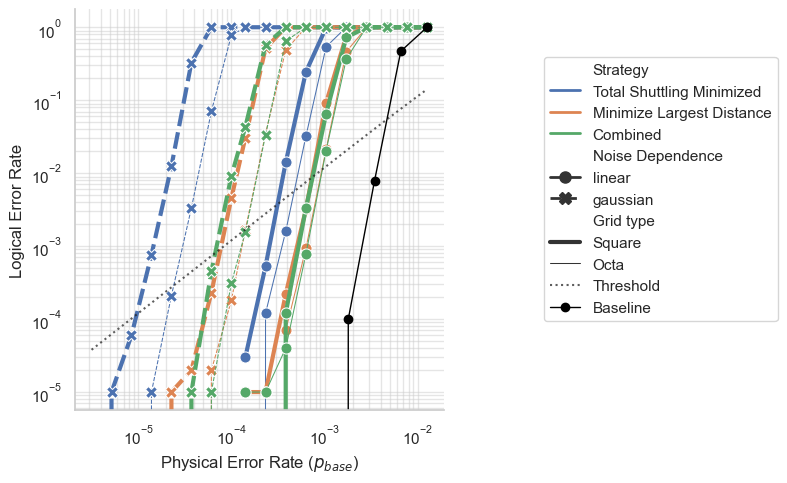

In [5]:
sns.set_theme(style="whitegrid")

base_df = baseline_df[(baseline_df["Polarization"] == "Depolarized")]

g = sns.relplot(
    data=df[(df["Polarization"] == "Depolarized") &
            (df["Noise Sources"] == "Full") &
            (df["Idling to Error Ratio"] == 1.8) &
            (df["Noise Dependence"].isin(["linear", "gaussian"])) &
            (df["Shuttling Error Ratio"] == 0.05)],# [

    kind="line",
    x="Physical Error Rate",
    y="Logical Error Rate",
    hue="Strategy",  # Perfect for comparing 'linear' vs 'gaussian'
    style="Noise Dependence",  # The "Polarization" can now easily distinguish bias vs no bias
#    row="Shuttling Error Ratio",
#    col="Noise Dependence",
    size="Grid type",
    markers=True,
    dashes=True,
    linewidth=2,
    markersize=8,
    height=5,
    aspect=1.2,
)

g.set(xscale="log", yscale="log")

min_p = df["Physical Error Rate"].min()
max_p = df["Physical Error Rate"].max()

x_vals = np.linspace(min_p, max_p,100)
y_vals = [1 - (1 - x_val)**12 for x_val in x_vals]

for ax in g.axes.flat:
    ax.plot(
        x_vals,
        y_vals,
        "k:",
        alpha=0.7,
        label="Threshold",
    )
    ax.grid(True, which="both", ls="-", alpha=0.5)

#Adds baseline plot into every plot of the grid.
for ax in g.axes.flat:
    ax.plot(
        base_df["Physical Error Rate"],
        base_df["Logical Error Rate"],
        color = "black",
        linestyle="-", 
        linewidth=1,
        marker="o",
        label="Baseline"
    )

g.set_axis_labels("Physical Error Rate ($p_{base}$)", "Logical Error Rate")


#Extract handles and labels from the existing sns legend
sns_handles = g.legend.legend_handles
sns_labels = [text.get_text() for text in g.legend.texts]

# Extract all handles/labels from the first axis
ax_handles, ax_labels = g.axes.flat[0].get_legend_handles_labels()

# Create a dictionary mapping the label names to their respective handles
ax_dict = dict(zip(ax_labels, ax_handles))

# Extract exactly the ones you want by name
custom_handles = [ax_dict["Threshold"], ax_dict["Baseline"]]
custom_labels = ["Threshold", "Baseline"]

#Combine the two handles and labels
handles = sns_handles + custom_handles
labels = sns_labels + custom_labels

#Remove sns-legend and add combined legend.
g.legend.remove()
plt.legend(
    handles=handles, 
    labels=labels, 
    bbox_to_anchor=(1.25, 0.9), 
    loc="upper left"
)


plt.tight_layout()
plt.show()

g.savefig(os.path.join(FIG_DIR, 'Comparison_plot_main.pdf'), metadata=PDF_METADATA)

### Extra plot, not in the paper

This cell shows the strategy comparison for both idling ratios (1 and 1.8) in one grid. The paper does not include this plot. The cell does not write a file.

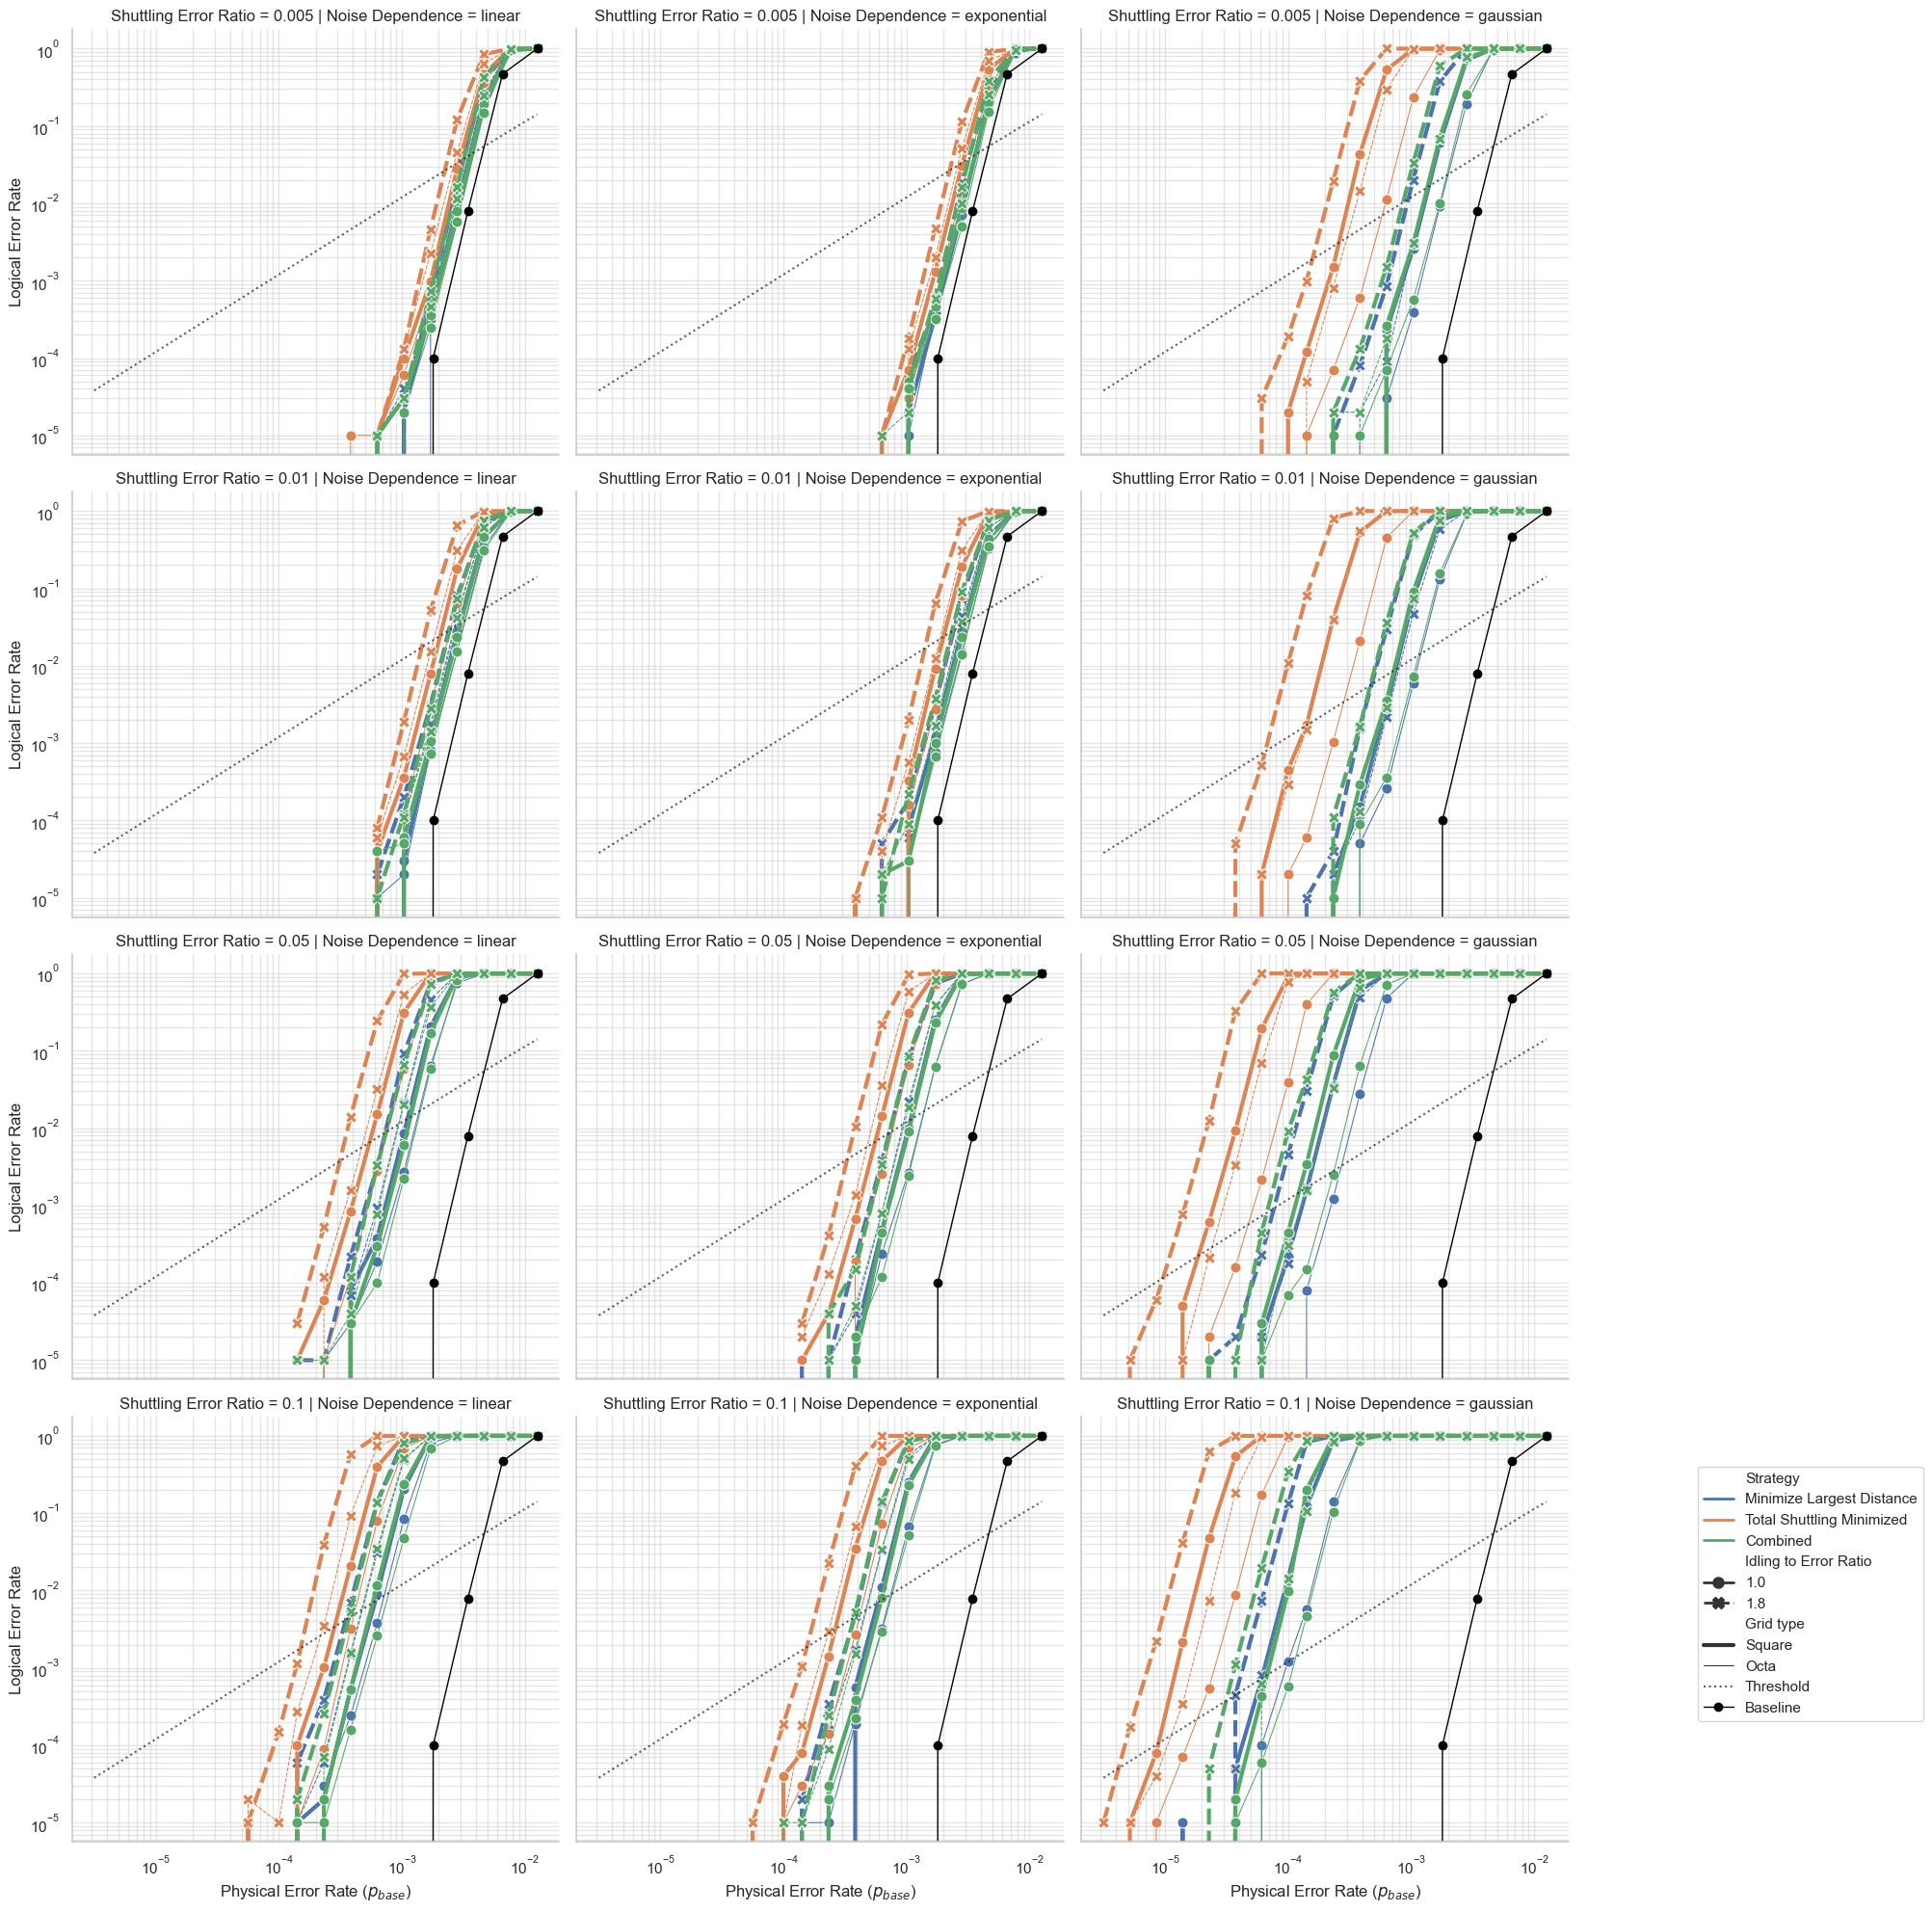

In [6]:
sns.set_theme(style="whitegrid")

base_df = baseline_df[(baseline_df["Polarization"] == "Depolarized")]

g = sns.relplot(
    data=df[(df["Polarization"] == "Depolarized") &
            (df["Noise Sources"] == "Full")],# [
    #     (df["Noise Sources"] == "Full")
    #     & (df["Idling Error Ratio"] == 0.0017)
    #     & (df["Noise Dependence"].isin(["linear", "gaussian"]))
    # ],
    kind="line",
    x="Physical Error Rate",
    y="Logical Error Rate",
    hue="Strategy",  # Perfect for comparing 'linear' vs 'gaussian'
    style="Idling to Error Ratio",  # The "Polarization" can now easily distinguish bias vs no bias
    row="Shuttling Error Ratio",
    col="Noise Dependence",
    size="Grid type",
    markers=True,
    dashes=True,
    linewidth=2,
    markersize=8,
    height=5,
    aspect=1.2,
)

g.set(xscale="log", yscale="log")

min_p = df["Physical Error Rate"].min()
max_p = df["Physical Error Rate"].max()

x_vals = np.linspace(min_p, max_p,100)
y_vals = [1 - (1 - x_val)**12 for x_val in x_vals]

for ax in g.axes.flat:
    ax.plot(
        x_vals,
        y_vals,
        "k:",
        alpha=0.7,
        label="Threshold",
    )
    ax.grid(True, which="both", ls="-", alpha=0.5)

#Adds baseline plot into every plot of the grid.
for ax in g.axes.flat:
    ax.plot(
        base_df["Physical Error Rate"],
        base_df["Logical Error Rate"],
        color = "black",
        linestyle="-", 
        linewidth=1,
        marker="o",
        label="Baseline"
    )

g.set_axis_labels("Physical Error Rate ($p_{base}$)", "Logical Error Rate")


#Extract handles and labels from the existing sns legend
sns_handles = g.legend.legend_handles
sns_labels = [text.get_text() for text in g.legend.texts]

# Extract all handles/labels from the first axis
ax_handles, ax_labels = g.axes.flat[0].get_legend_handles_labels()

# Create a dictionary mapping the label names to their respective handles
ax_dict = dict(zip(ax_labels, ax_handles))

# Extract exactly the ones you want by name
custom_handles = [ax_dict["Threshold"], ax_dict["Baseline"]]
custom_labels = ["Threshold", "Baseline"]

#Combine the two handles and labels
handles = sns_handles + custom_handles
labels = sns_labels + custom_labels

#Remove sns-legend and add combined legend.
g.legend.remove()
plt.legend(
    handles=handles, 
    labels=labels, 
    bbox_to_anchor=(1.25, 0.9), 
    loc="upper left"
)


plt.tight_layout()
plt.show()

#g.savefig('Comparison_plot_appendix.pdf')

### Figure 9 (Appendix C)

This cell writes `figures/Comparison_polarization_appendix.pdf`. The paper uses this file as Figure 9.

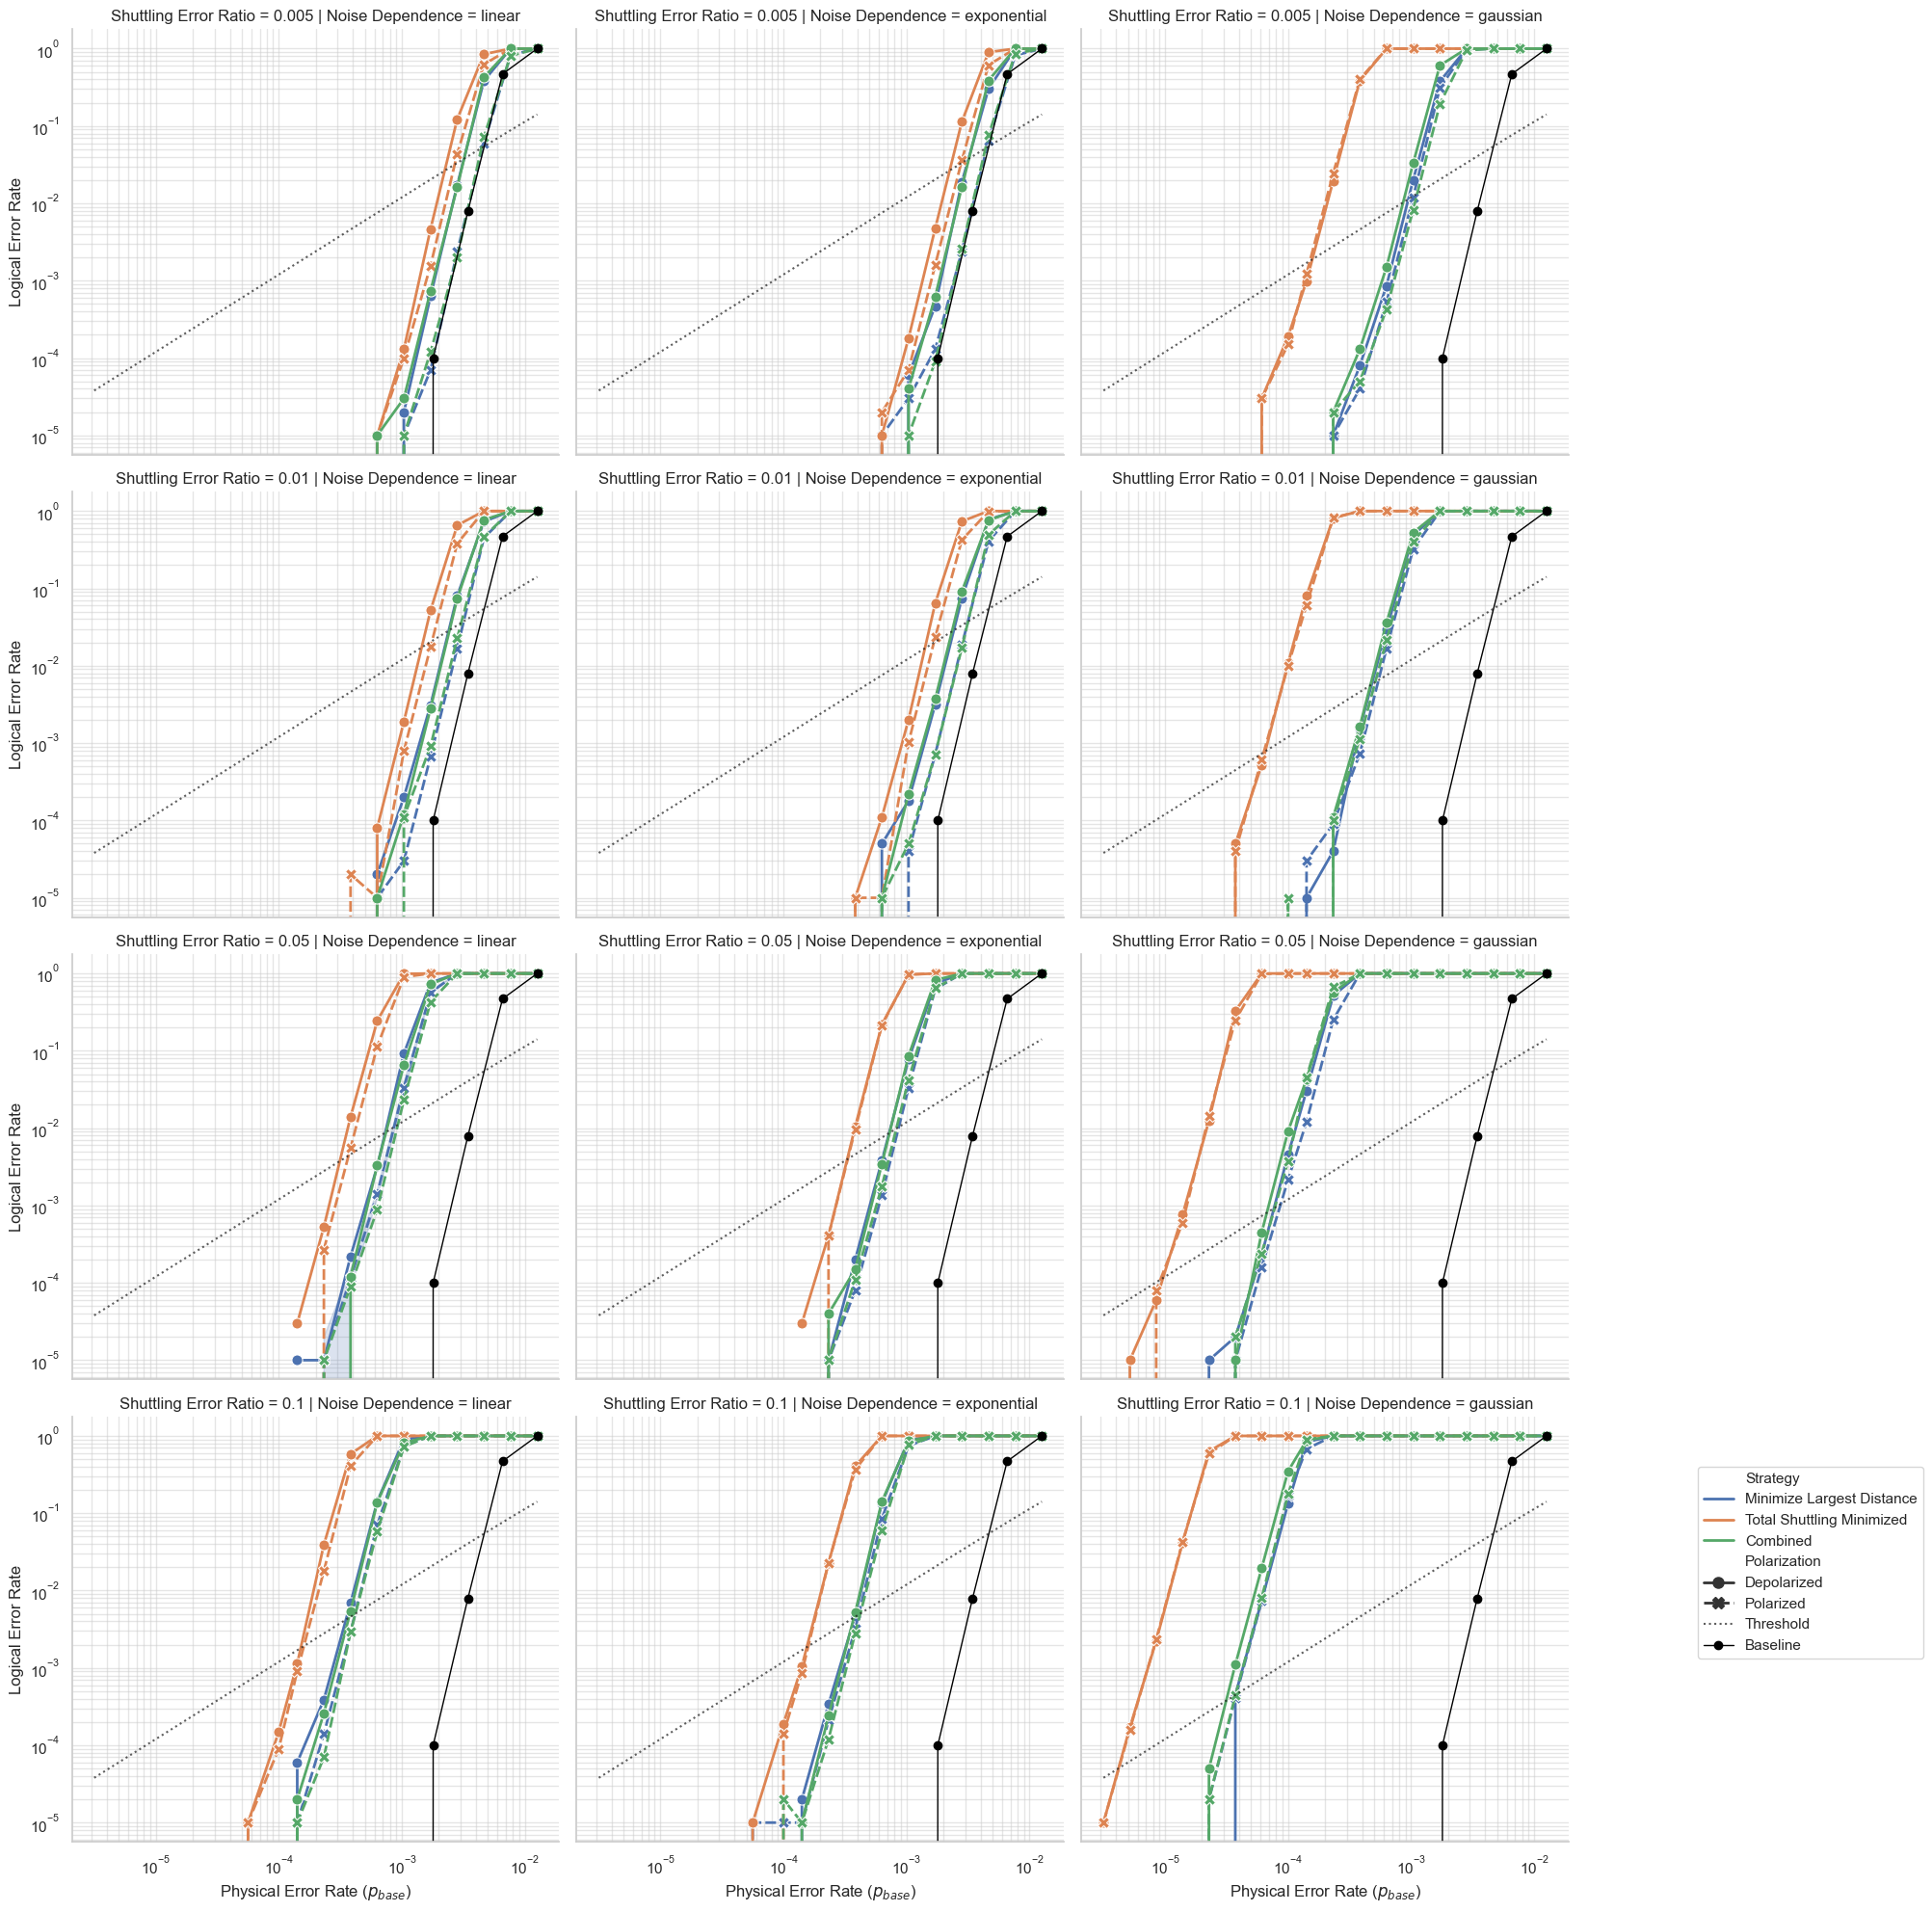

In [7]:
sns.set_theme(style="whitegrid")


base_df = baseline_df[(baseline_df["Polarization"] == "Depolarized")]

g = sns.relplot(
    data=df[(df["Grid type"] == "Square") &
            (df["Noise Sources"] == "Full") &
            (df["Idling to Error Ratio"] == 1.8)],# [
    #     (df["Noise Sources"] == "Full")
    #     & (df["Idling Error Ratio"] == 0.0017)
    #     & (df["Noise Dependence"].isin(["linear", "gaussian"]))
    # ],
    kind="line",
    x="Physical Error Rate",
    y="Logical Error Rate",
    hue="Strategy",  # Perfect for comparing 'linear' vs 'gaussian'
    style="Polarization",  # The "Polarization" can now easily distinguish bias vs no bias
    row="Shuttling Error Ratio",
    col="Noise Dependence",
    #size="Polarization",
    markers=True,
    dashes=True,
    linewidth=2,
    markersize=8,
    height=5,
    aspect=1.2,
)

g.set(xscale="log", yscale="log")

min_p = df["Physical Error Rate"].min()
max_p = df["Physical Error Rate"].max()

x_vals = np.linspace(min_p, max_p,100)
y_vals = [1 - (1 - x_val)**12 for x_val in x_vals]

for ax in g.axes.flat:
    ax.plot(
        x_vals,
        y_vals,
        "k:",
        alpha=0.7,
        label="Threshold",
    )
    ax.grid(True, which="both", ls="-", alpha=0.5)

#Adds baseline plot into every plot of the grid.
for ax in g.axes.flat:
    ax.plot(
        base_df["Physical Error Rate"],
        base_df["Logical Error Rate"],
        color = "black",
        linestyle="-", 
        linewidth=1,
        marker="o",
        label="Baseline"
    )

# for ax in g.axes.flat:
#     ax.plot(
#         [min_p, max_p],
#         [12*min_p, 12*max_p],
#         "k:",
#         alpha=0.7,
#         label="Threshold",
#     )
#     ax.grid(True, which="both", ls="-", alpha=0.5)

g.set_axis_labels("Physical Error Rate ($p_{base}$)", "Logical Error Rate")


#Extract handles and labels from the existing sns legend
sns_handles = g.legend.legend_handles
sns_labels = [text.get_text() for text in g.legend.texts]

# Extract all handles/labels from the first axis
ax_handles, ax_labels = g.axes.flat[0].get_legend_handles_labels()

# Create a dictionary mapping the label names to their respective handles
ax_dict = dict(zip(ax_labels, ax_handles))

# Extract exactly the ones you want by name
custom_handles = [ax_dict["Threshold"], ax_dict["Baseline"]]
custom_labels = ["Threshold", "Baseline"]

#Combine the two handles and labels
handles = sns_handles + custom_handles
labels = sns_labels + custom_labels

#Remove sns-legend and add combined legend.
g.legend.remove()
plt.legend(
    handles=handles, 
    labels=labels, 
    bbox_to_anchor=(1.25, 0.9), 
    loc="upper left"
)


plt.tight_layout()
plt.show()

g.savefig(os.path.join(FIG_DIR, 'Comparison_polarization_appendix.pdf'), metadata=PDF_METADATA)

## Initial layout datasweep

Load the initial layout datasweep. Then give the parameters readable names.

In [8]:
df_2 = pd.read_csv(os.path.join(DATA_DIR, 'compiled_results_initial_positions.csv'))


In [9]:
df_2["Strategy"] = df_2["Strategy"].replace("total_shuttling_minimized","Total Shuttling Minimized")
df_2["Strategy"] = df_2["Strategy"].replace("maximum_matching_efficient","Minimize Largest Distance")
df_2["Strategy"] = df_2["Strategy"].replace("min_weight_matching_efficient","Combined")

df_2 = df_2.rename(columns={"Noise Model" : "Noise Dependence", "Eta Shuttling" : "Polarization", "2 Qubit Gate Error" : "Noise Sources"})

df_2["Polarization"] = df_2["Polarization"].replace(0.5, "Depolarized")
df_2["Polarization"] = df_2["Polarization"].replace(100, "Polarized")


df_2["Noise Sources"] = df_2["Noise Sources"].replace(1.0, "Full")
df_2["Noise Sources"] = df_2["Noise Sources"].replace(0, "Shuttling & Idling")




In [10]:
df_2["Initial Layout"]

0             random25
1             random25
2             random25
3             random25
4             random25
             ...      
10435    folded Tanner
10436    folded Tanner
10437    folded Tanner
10438    folded Tanner
10439    folded Tanner
Name: Initial Layout, Length: 10440, dtype: object

### Figure 7 (Appendix C)

This cell writes `figures/Initial_layout_appendix.pdf`. The paper uses this file as Figure 7.

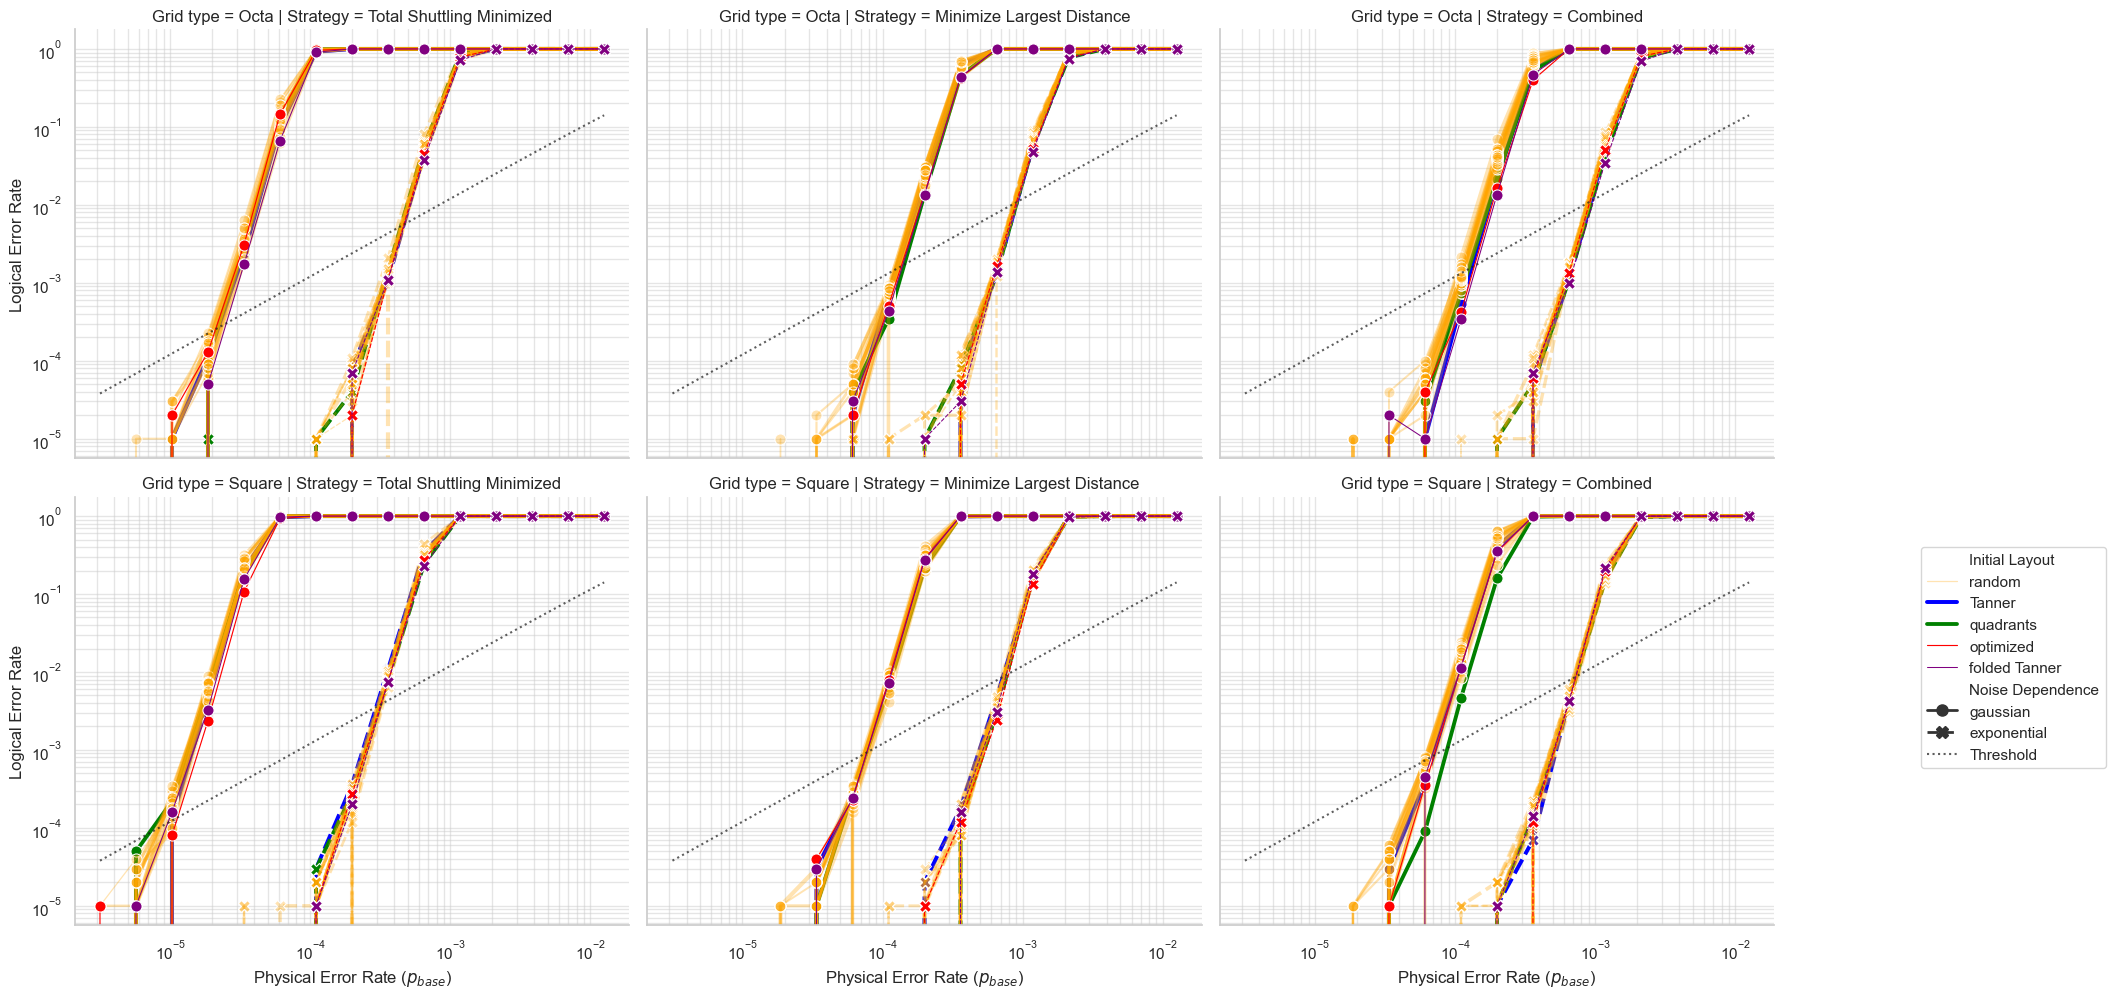

In [11]:
#Comparison of Initial Layouts. Displays them for different strategies, noise models, and grid types. The Noise Sources is set to 1. The Shuttling Error ratio is 0.05
sns.set_theme(style="whitegrid")


# random_colour = {f'random{i}' : (230/255, 159/255, 0/255, 0.3) for i in range(1,26)}
# hue_palette = {
#     **random_colour,
#     'Tanner' : (34/255,113/255,178/255,1),
#     'folded Tanner' : (61/255, 183/255, 233/255,1),
#     'optimized' : (213/255, 94/255, 0/255, 1),
#     'quadrants' : (53/255, 155/255, 115/255, 1)
# }

random_colour = {f'random{i}' : to_rgba("orange", alpha=0.3) for i in range(1,26)}
hue_palette = {
    **random_colour,
    'Tanner' : to_rgba("blue", alpha=1),
    'folded Tanner' : to_rgba("purple", alpha=1),
    'optimized' : to_rgba("red", alpha=1),
    'quadrants' : to_rgba("green", alpha=1)
}

g = sns.relplot(
    data=df_2[(df_2["Noise Sources"] == "Full") &
            (df_2["Shuttling Error Ratio"] == 0.05)
            ],
    kind="line",
    x="Physical Error Rate",
    y="Logical Error Rate",
    hue="Initial Layout",
    palette=hue_palette, #Adds a custom palette for the hues. This assumes that the hue is for the initial layouts!
    style="Noise Dependence",
    row="Grid type",
    col="Strategy",
    size="Initial Layout",
    markers=True,
    dashes=True,
    linewidth=2,
    markersize=8,
    height=5,
    aspect=1.2,
)

g.set(xscale="log", yscale="log")

min_p = df_2["Physical Error Rate"].min()
max_p = df_2["Physical Error Rate"].max()

x_vals = np.linspace(min_p, max_p,100)
y_vals = [1 - (1 - x_val)**12 for x_val in x_vals]

for ax in g.axes.flat:
    ax.plot(
        x_vals,
        y_vals,
        "k:",
        alpha=0.7,
        label="Threshold",
    )
    ax.grid(True, which="both", ls="-", alpha=0.5)

g.set_axis_labels("Physical Error Rate ($p_{base}$)", "Logical Error Rate")


#Extract handles and labels from the existing sns legend
sns_handles = g.legend.legend_handles
sns_labels = [text.get_text() for text in g.legend.texts]
sns_labels_modified = ['random' if label.startswith('random') else label for label in sns_labels]

#Extract the custom handle and label from one of the axes
#Since the line was plotted on all axes, we can just pull from the first one
ax_handles, ax_labels = g.axes.flat[0].get_legend_handles_labels()
custom_handle = ax_handles[-1] # The last item added is our custom line
custom_label = ax_labels[-1]

#Combine the two handles and labels
handles = sns_handles + [custom_handle]
labels = sns_labels_modified + [custom_label]
legend = dict(zip(labels,handles))

#Remove sns-legend and add combined legend.
g.legend.remove()
plt.legend(
    handles=legend.values(), 
    labels=legend.keys(), 
    bbox_to_anchor=(1.25, 0.9), 
    loc="upper left"
)


plt.show()

g.savefig(os.path.join(FIG_DIR, 'Initial_layout_appendix.pdf'), metadata=PDF_METADATA)

### Figure 3

This cell writes `figures/Initial_layout_main.pdf`. The paper shows this plot as Figure 3 (file `Initial_layout_main_publication.pdf`). The published version has a manually moved legend and layout.

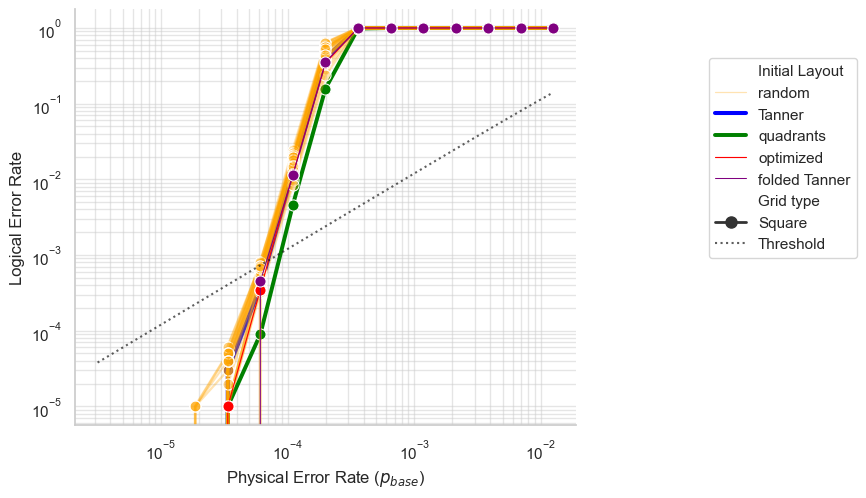

In [12]:
#Compares the different Initial layouts for the min_weight_matching_efficient strategy, a gaussian Noise Dependence and the Squaregrid. The Noise Sources is set to 1. The Shuttling Error ratio is 0.05
sns.set_theme(style="whitegrid")


#df_2['Initial Layout'] = df_2['Initial Layout'].str.replace(r'^random.*', 'random', regex=True)

# random_colour = {f'random{i}' : (230/255, 159/255, 0/255, 0.3) for i in range(1,26)}
# hue_palette = {
#     **random_colour,
#     'Tanner' : (34/255,113/255,178/255,1),
#     'folded Tanner' : (61/255, 183/255, 233/255,1),
#     'optimized' : (213/255, 94/255, 0/255, 1),
#     'quadrants' : (53/255, 155/255, 115/255, 1)
# }

random_colour = {f'random{i}' : to_rgba("orange", alpha=0.3) for i in range(1,26)}
hue_palette = {
    **random_colour,
    'Tanner' : to_rgba("blue", alpha=1),
    'folded Tanner' : to_rgba("purple", alpha=1),
    'optimized' : to_rgba("red", alpha=1),
    'quadrants' : to_rgba("green", alpha=1)
}

g = sns.relplot(
    data=df_2[(df_2["Noise Sources"] == "Full") &
            (df_2["Shuttling Error Ratio"] == 0.05) &
            (df_2["Strategy"] == "Combined") &
            (df_2["Noise Dependence"] == "gaussian") &
            (df_2["Grid type"] == "Square")
            ],
    kind="line",
    x="Physical Error Rate",
    y="Logical Error Rate",
    hue="Initial Layout",
    palette=hue_palette, #Adds a custom palette for the hues. This assumes that the hue is for the initial layouts!
    style="Grid type",
    size="Initial Layout",
    markers=True,
    dashes=True,
    linewidth=2,
    markersize=8,
    height=5,
    aspect=1.2,
)

g.set(xscale="log", yscale="log")

min_p = df_2["Physical Error Rate"].min()
max_p = df_2["Physical Error Rate"].max()

x_vals = np.linspace(min_p, max_p,100)
y_vals = [1 - (1 - x_val)**12 for x_val in x_vals]

for ax in g.axes.flat:
    ax.plot(
        x_vals,
        y_vals,
        "k:",
        alpha=0.7,
        label="Threshold",
    )
    ax.grid(True, which="both", ls="-", alpha=0.5)

g.set_axis_labels("Physical Error Rate ($p_{base}$)", "Logical Error Rate")


#Extract handles and labels from the existing sns legend
sns_handles = g.legend.legend_handles
sns_labels = [text.get_text() for text in g.legend.texts]
sns_labels_modified = ['random' if label.startswith('random') else label for label in sns_labels]

#Extract the custom handle and label from one of the axes
#Since the line was plotted on all axes, we can just pull from the first one
ax_handles, ax_labels = g.axes.flat[0].get_legend_handles_labels()
custom_handle = ax_handles[-1] # The last item added is our custom line
custom_label = ax_labels[-1]

#Combine the two handles and labels
handles = sns_handles + [custom_handle]
labels = sns_labels_modified + [custom_label]
legend = dict(zip(labels,handles))

#Remove sns-legend and add combined legend.
g.legend.remove()
plt.legend(
    handles=legend.values(), 
    labels=legend.keys(), 
    bbox_to_anchor=(1.25, 0.9), 
    loc="upper left"
)


plt.show()

g.savefig(os.path.join(FIG_DIR, 'Initial_layout_main.pdf'), metadata=PDF_METADATA)